# Assignment: Preprocessing Data for scikit learn
### Dataset: UCI Mushroom Dataset (`agaricus-lepiota.data`)
### Columns Selected: `edible_poisonous` (class), `odor`, and `cap_color`

In [1]:
!pip install pandas
!pip install matplotlib
!pip install seaborn

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## loads the raw mushroom dataset directly from the UCI repo
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data"

## data dictionary:
## column 0 = class (e=edible, p=poisonous)
## column 3 = cap-color (n=brown, b=buff, c=cinnamon, g=gray, r=green, p=pink, u=purple, e=red, w=white, y=yellow)
## column 5 = odor (a=almond, l=anise, c=creosote, y=fishy, f=foul, m=musty, n=none, p=pungent, s=spicy)
raw_df = pd.read_csv(url, header=None)

## subsets the three columns and assigns them meaningful names
df = raw_df[[0, 5, 3]].copy()
df.columns = ['edible_poisonous', 'odor', 'cap_color']

df.head()

,edible_poisonous,odor,cap_color
0,p,p,n
1,e,a,y
2,e,l,w
3,p,p,w
4,e,n,g


In [3]:
## maps the target column: edible ('e') = 0, poisonous ('p') = 1
df['edible_poisonous'] = df['edible_poisonous'].map({'e': 0, 'p': 1})

## maps the odor codes to numeric values
odor_map = {
    'a': 0, 'l': 1, 'c': 2, 'y': 3, 'f': 4,
    'm': 5, 'n': 6, 'p': 7, 's': 8
}
df['odor'] = df['odor'].map(odor_map)

## maps the cap_color codes to numeric values
color_map = {
    'n': 0, 'b': 1, 'c': 2, 'g': 3, 'r': 4,
    'p': 5, 'u': 6, 'e': 7, 'w': 8, 'y': 9
}
df['cap_color'] = df['cap_color'].map(color_map)

## confirms that all columns are now integers with no missing values
print(df.dtypes)
df.head()

edible_poisonous    int64
odor                int64
cap_color           int64
dtype: object


,edible_poisonous,odor,cap_color
0,1,7,0
1,0,0,9
2,0,1,8
3,1,7,8
4,0,6,3


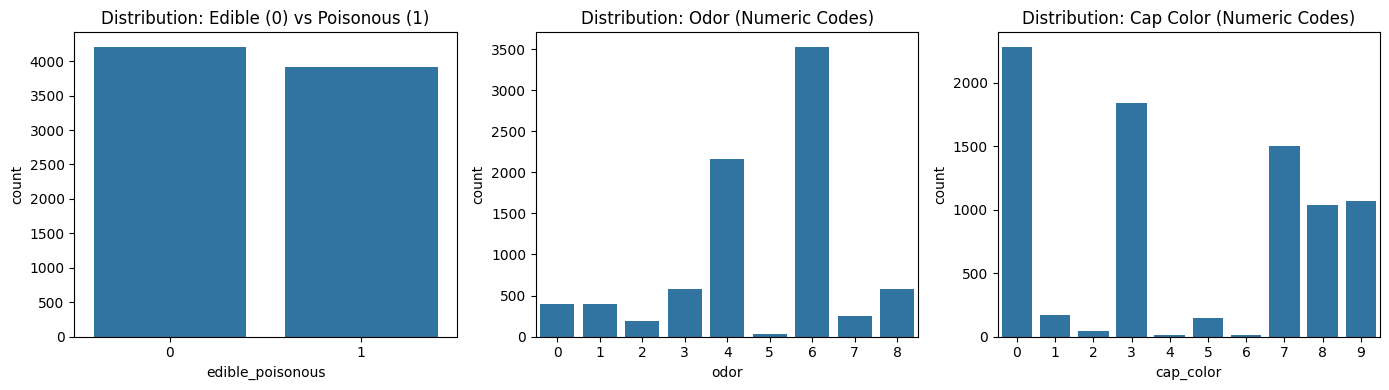

In [4]:
## shows the distribution for each of the selected columns
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

sns.countplot(x='edible_poisonous', data=df, ax=axes[0])
axes[0].set_title('Distribution: Edible (0) vs Poisonous (1)')

sns.countplot(x='odor', data=df, ax=axes[1])
axes[1].set_title('Distribution: Odor (Numeric Codes)')

sns.countplot(x='cap_color', data=df, ax=axes[2])
axes[2].set_title('Distribution: Cap Color (Numeric Codes)')

plt.tight_layout()
plt.show()

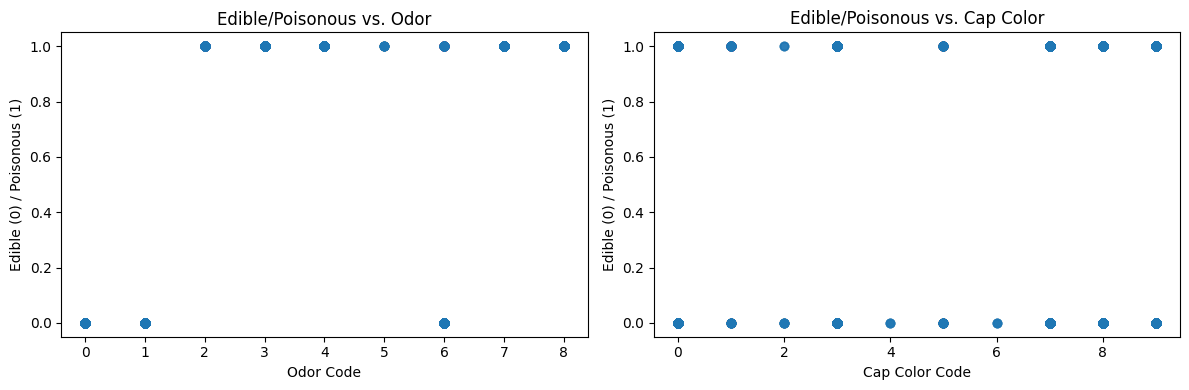

In [5]:
## scatterplots that are comparing edible_poisonous against odor and cap_color
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(df['odor'], df['edible_poisonous'], alpha=0.2)
axes[0].set_title('Edible/Poisonous vs. Odor')
axes[0].set_xlabel('Odor Code')
axes[0].set_ylabel('Edible (0) / Poisonous (1)')

axes[1].scatter(df['cap_color'], df['edible_poisonous'], alpha=0.2)
axes[1].set_title('Edible/Poisonous vs. Cap Color')
axes[1].set_xlabel('Cap Color Code')
axes[1].set_ylabel('Edible (0) / Poisonous (1)')

plt.tight_layout()
plt.show()

### Conclusion
Based on the plots, odor looks like a very strong predictor of whether a mushroom is edible or poisonous. In the scatterplot, almost every specific odor code falls cleanly into either the edible (`0`) or poisonous (`1`) row with very little overlap,for instance, almond (`0`) and anise (`1`) only appear on edible mushrooms, while foul (`4`), fishy (`3`), pungent (`7`), and spicy (`8`) only appear on poisonous ones.

On the other hand, cap_color does not seem nearly as helpful on its own. Most cap colors show up in both the edible and poisonous groups, meaning color alone wouldn't reliably separate the two classes in a predictive model without combining it with stronger features like odor.